This notebook is very similar to Distance_Plots, but we add a cap to N_ion for the SPDC-M.
We find the caps for both PSet I and PSet II with some trial and error, these are approximate values where if you go much below, a solution can not be found at all distances that satisfies N_ion < N_cap, and F = F_target

The caps used here are 300 and 6000 for PSet I and PSet II

In [1]:
using CairoMakie
using LaTeXStrings
include("Protocol_Fns.jl")
using Logging
global_logger(ConsoleLogger())   # new logger for error message (since it only outputs once per kernel if you don't do this), maxlog counts start from zero

ConsoleLogger(IJulia.IJuliaStdio{Base.PipeEndpoint}(IOContext(Base.PipeEndpoint(Base.Libc.WindowsRawSocket(0x00000000000003c4) open, 0 bytes waiting))), ReentrantLock(), Info, Base.CoreLogging.default_metafmt, true, 0, Dict{Any, Int64}())

In [2]:
##### parameters set I - optimistic values

N_cap = 300
F_targ= 0.9 #target fidelity
η_m, η_FC, η_i_io = fill(0.8,3)
η_d, η_AFC0 = fill(0.9,2)
η_herald = 0.97
effs = (η_m, η_d, η_i_io, η_FC, η_AFC0, η_herald);
effs_SPDC = (η_m, η_d, η_i_io, η_FC, η_herald);
N_bin=10 
M=1000 #multiplexing modes
r=0.4 #dephasing parameter
epsilon_m=0.5; nu = 1; Lambda_0= nu/2; filt_params = (Lambda_0, nu, epsilon_m); #low pass filter parameters
T_EN = 10*1e-6; #effective time between ion pulse attempts

In [3]:
###Generate data

L_array = range(50,500,length=50)*1e3 #range of total distances, in meters
M_M_results = Dict(); #initialize memory matching results

for (sc_label, sc_key) in [(:SC, true), (:DC, false)]
    for (repeater_label, repeater_key) in [(:repeater, 1), (:no_repeater, 0)]
        for (turn_label, turn_key) in [(:on, false), (:off, true)]
            M_M_results[(sc_label, turn_label, repeater_label)] = map(L -> Memory_Match(
                repeater_key, L, effs, F_targ, M, filt_params;
                single_click = sc_key,
                r = r,
                turn_off = turn_key
            ), L_array)
        end
    end
end
#We can access the parameters,
#T_ent, T_m_w, T_i_w, N_ion, P_i, P_SPDC, F_0 = M_M_results[(:SC/:DC, :on/:off, :repeater/:no_repeater)],
#Where each of the output is a vector as a function of distance

SPDC_M_results = Dict();
# We tie the SPDC (memory) turn-off to the ion turn-off. For SC it has no effect at the order considered; for DC it enters only through I_0 and κ_0 (a small effect).
for (sc_label, sc_key) in [(:SC, true), (:DC, false)]
    for (repeater_label, repeater_key) in [(:repeater, 1), (:no_repeater, 0)]
        for (turn_label, turn_key) in [(:on, false), (:off, true)]
            SPDC_M_results[(sc_label, turn_label, repeater_label)] = map(L -> SPDC_Match(
                repeater_key, L, effs_SPDC, F_targ, M, N_bin, T_EN;
                single_click = sc_key,
                r = r,
                N_cap = N_cap,
                turn_off = turn_key,
                turn_off_mem = turn_key
            ), L_array)
        end
    end
end
#We can access the parameters,
#T_ent, T_m_w, T_i_w, N_ion, P_i, P_SPDC, P_b = SPDC_M_results[(:SC/:DC, :on/:off, :repeater/:no_repeater)],
#Where each of the output is a vector as a function of distance

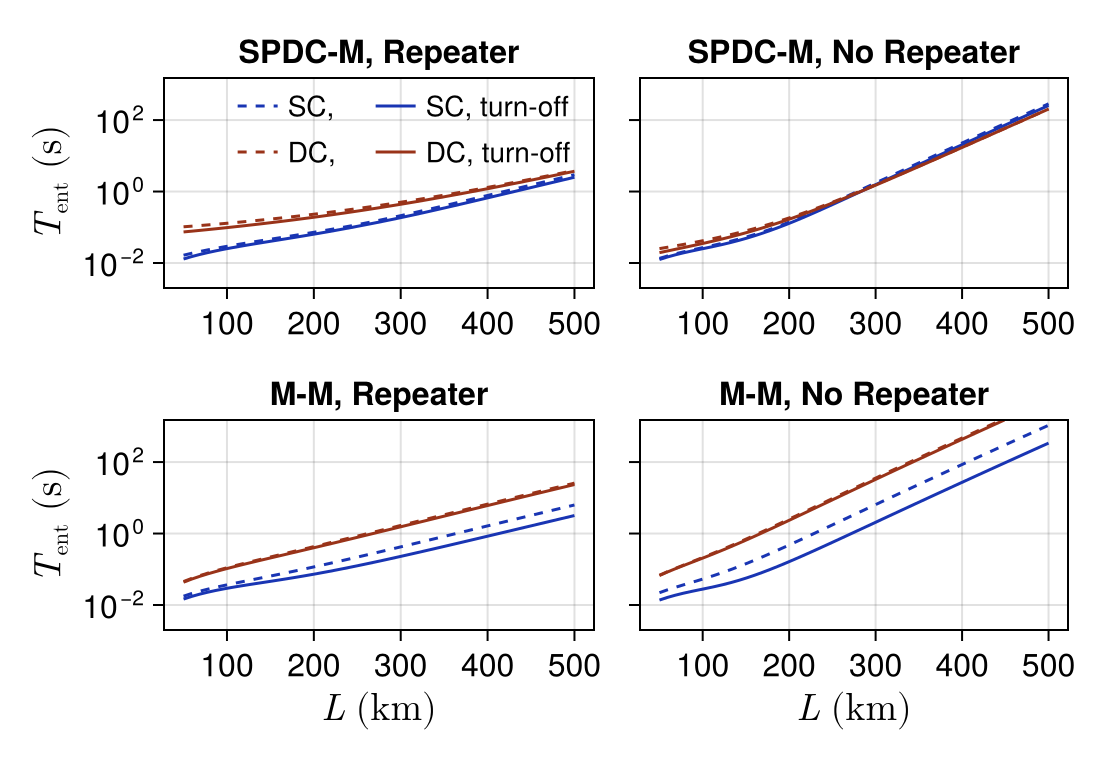

In [4]:
fig1 = Figure(size = (550, 380))
C_red  = RGBf(0.6,0.2,0.1); C_blue = RGBf(0.1,0.21,0.7)
f_size, t_size, y_size, leg_size = 16, 16, 19, 14
ylm = (2e-3, 1.5e3);
colors = Dict(:SC => C_blue, :DC => C_red)
linestyles = Dict(:on => :dash, :off => :solid)
linestyle_labels = Dict(:on => "", :off  => "turn-off")
titles = [    "SPDC-M, Repeater"        "SPDC-M, No Repeater"; "M-M, Repeater"      "M-M, No Repeater"]
for (i, dataset) in enumerate((SPDC_M_results, M_M_results))
    for (j, repeater_label) in enumerate((:repeater, :no_repeater))
        ax = Axis(fig1[i, j],ylabel = j ==  1 ?  L"T_{\mathrm{ent}} \  \mathrm{(s)}" : "", yticklabelsvisible = (j == 1),xlabel = i == 2 ?  L"L\;(\mathrm{km})" : "", yscale = log10, title = titles[i,j], xlabelsize = y_size, ylabelsize = y_size, titlesize = t_size, xticklabelsize = f_size, yticklabelsize = f_size)
        ylims!(ax, ylm)
        for sc_label in (:SC, :DC)
            for turn_label in (:on, :off)
                T_ent = first.(dataset[(sc_label, turn_label, repeater_label)])
                lines!(ax, L_array ./ 1e3, T_ent; color = colors[sc_label], linestyle = linestyles[turn_label], label = "$(sc_label), $(linestyle_labels[turn_label])")
            end
        end
        if i == 1 && j == 1 axislegend(ax; position= (1., 1.2),nbanks = 2, framevisible = false,labelsize=leg_size) end #Add legend
    end
end
fig1

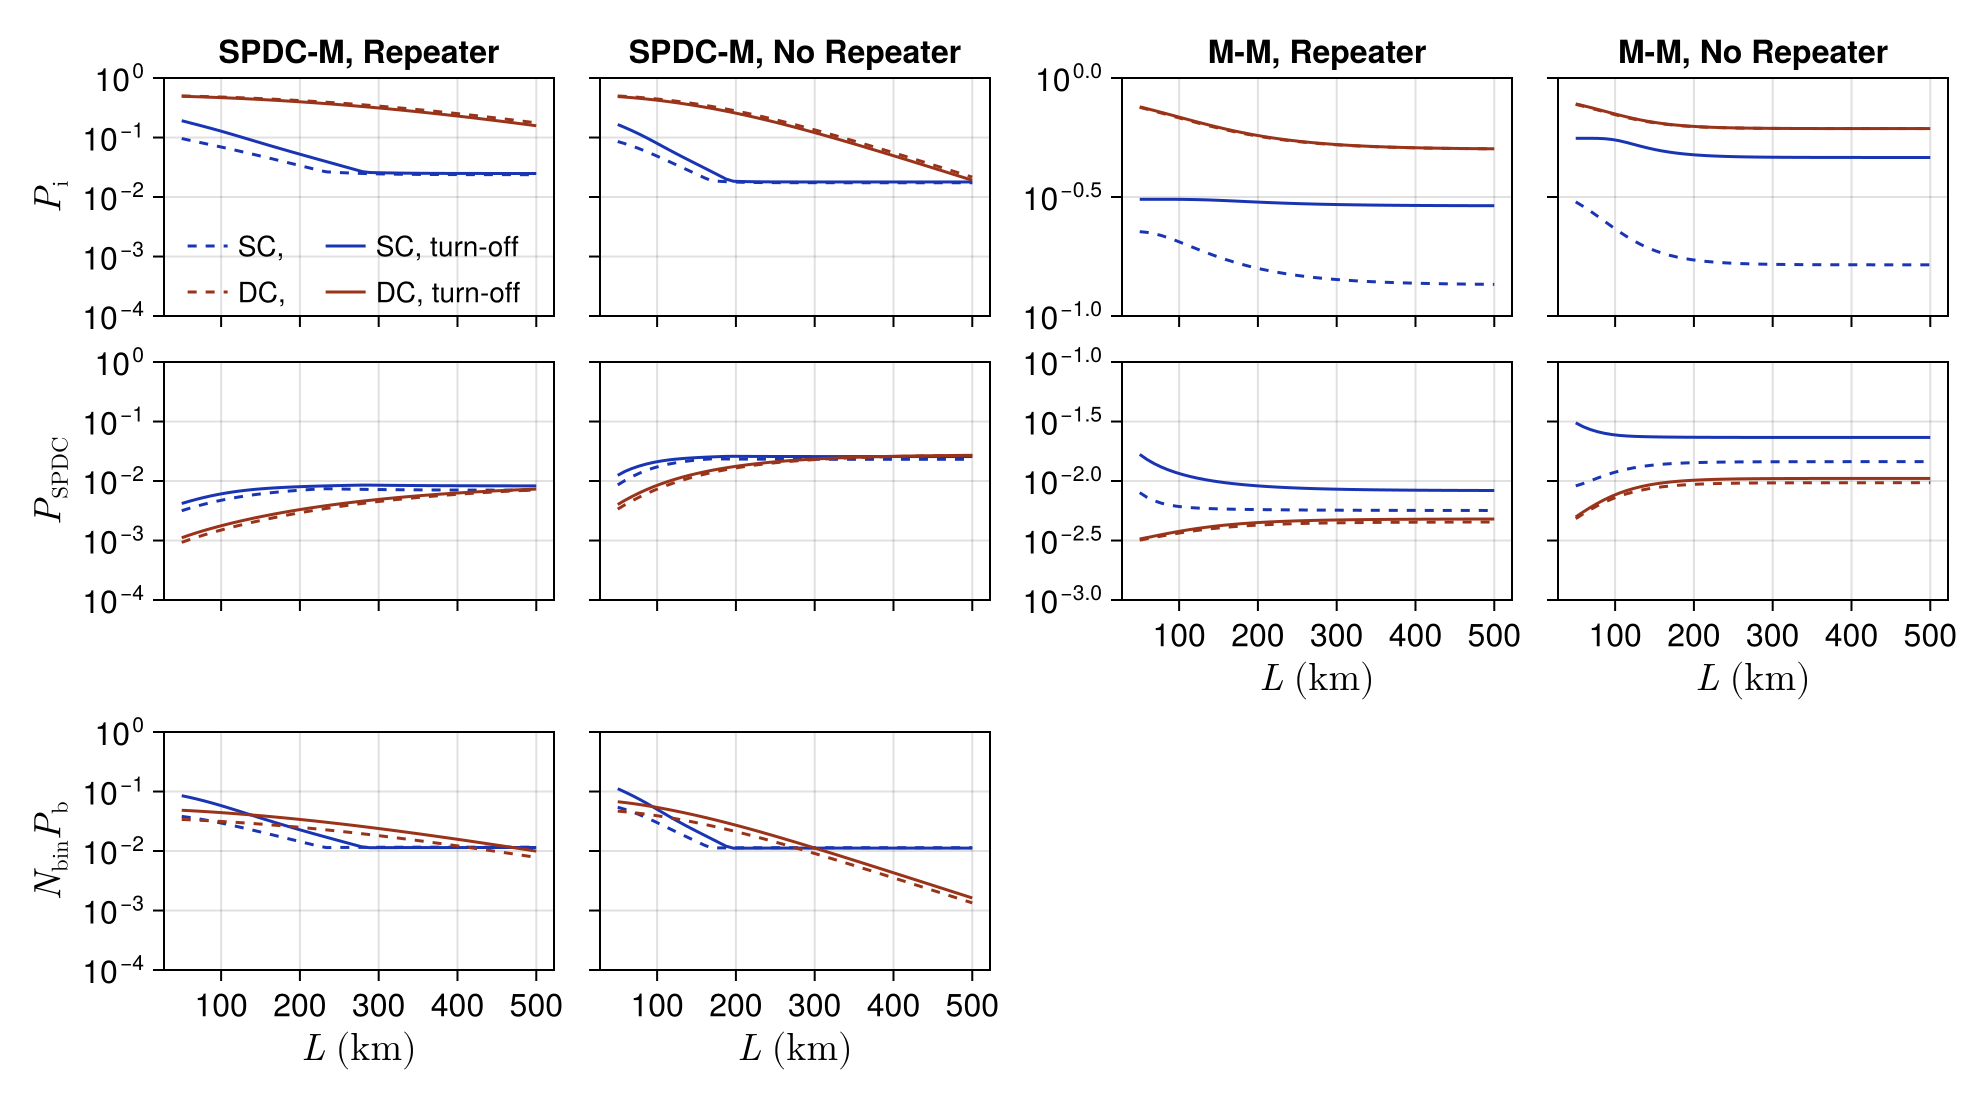

In [5]:
#Check here that all photon probabilities are in their appropriate perturbative regime

fig2 = Figure(size = (990, 550))

ylm = (1e-4, 1)
titles = ["SPDC-M, Repeater"  "SPDC-M, No Repeater"]
rows = [(5, L"P_{\mathrm{i}}"), (6, L"P_{\mathrm{SPDC}}"), (7, L"N_{\mathrm{bin}}P_{\mathrm{b}}")]

for (j, repeater_label) in enumerate((:repeater, :no_repeater))
    for (row, (idx, ylab)) in enumerate(rows)
        ax = Axis(fig2[row, j], ylabel = j == 1 ? ylab : "", xlabel = row == 3 ? L"L\;(\mathrm{km})" : "", yscale = log10, yticklabelsvisible = (j == 1), xticklabelsvisible = (row == 3),
            title = row == 1 ? titles[j] : "", xlabelsize = y_size, ylabelsize = y_size, titlesize = t_size, xticklabelsize = f_size, yticklabelsize = f_size)
        ylims!(ax, ylm)
        for sc_label in (:SC, :DC), turn_label in (:on, :off)
            vals = getindex.(SPDC_M_results[(sc_label, turn_label, repeater_label)], idx)
            fac = row == 3 ? N_bin : 1
            lines!(ax, L_array ./ 1e3, vals*fac; color = colors[sc_label], linestyle = linestyles[turn_label], label = "$(sc_label), $(linestyle_labels[turn_label])")
        end
        if row == 1 && j == 1 axislegend(ax; position= (0., -0.2),nbanks = 2, framevisible = false,labelsize=leg_size) end
    end
end

titles2 = ["M-M, Repeater"  "M-M, No Repeater"]
rows2 = [(5, L"P_{\mathrm{i}}"), (6, L"P_{\mathrm{SPDC}}")]
ylm2 = (1e-1, 1); ylm3 = (1e-3,1e-1);
for (j, repeater_label) in enumerate((:repeater, :no_repeater))
    for (row, (idx, ylab)) in enumerate(rows2)
        ax = Axis(fig2[row, j + 2], ylabel = "", xlabel = row == 2 ? L"L\;(\mathrm{km})" : "", yscale = log10, yticklabelsvisible = (j==1), xticklabelsvisible = (row == 2),
            title = row == 1 ? titles2[j] : "", xlabelsize = y_size, ylabelsize = y_size, titlesize = t_size, xticklabelsize = f_size, yticklabelsize = f_size)
        if row == 1 ylims!(ax, ylm2) else ylims!(ax, ylm3) end
        for sc_label in (:SC, :DC), turn_label in (:on, :off)
            vals = getindex.(M_M_results[(sc_label, turn_label, repeater_label)], idx)
            lines!(ax, L_array ./ 1e3, vals; color = colors[sc_label], linestyle = linestyles[turn_label], label = "$(sc_label), $(linestyle_labels[turn_label])")
        end
    end
end

fig2

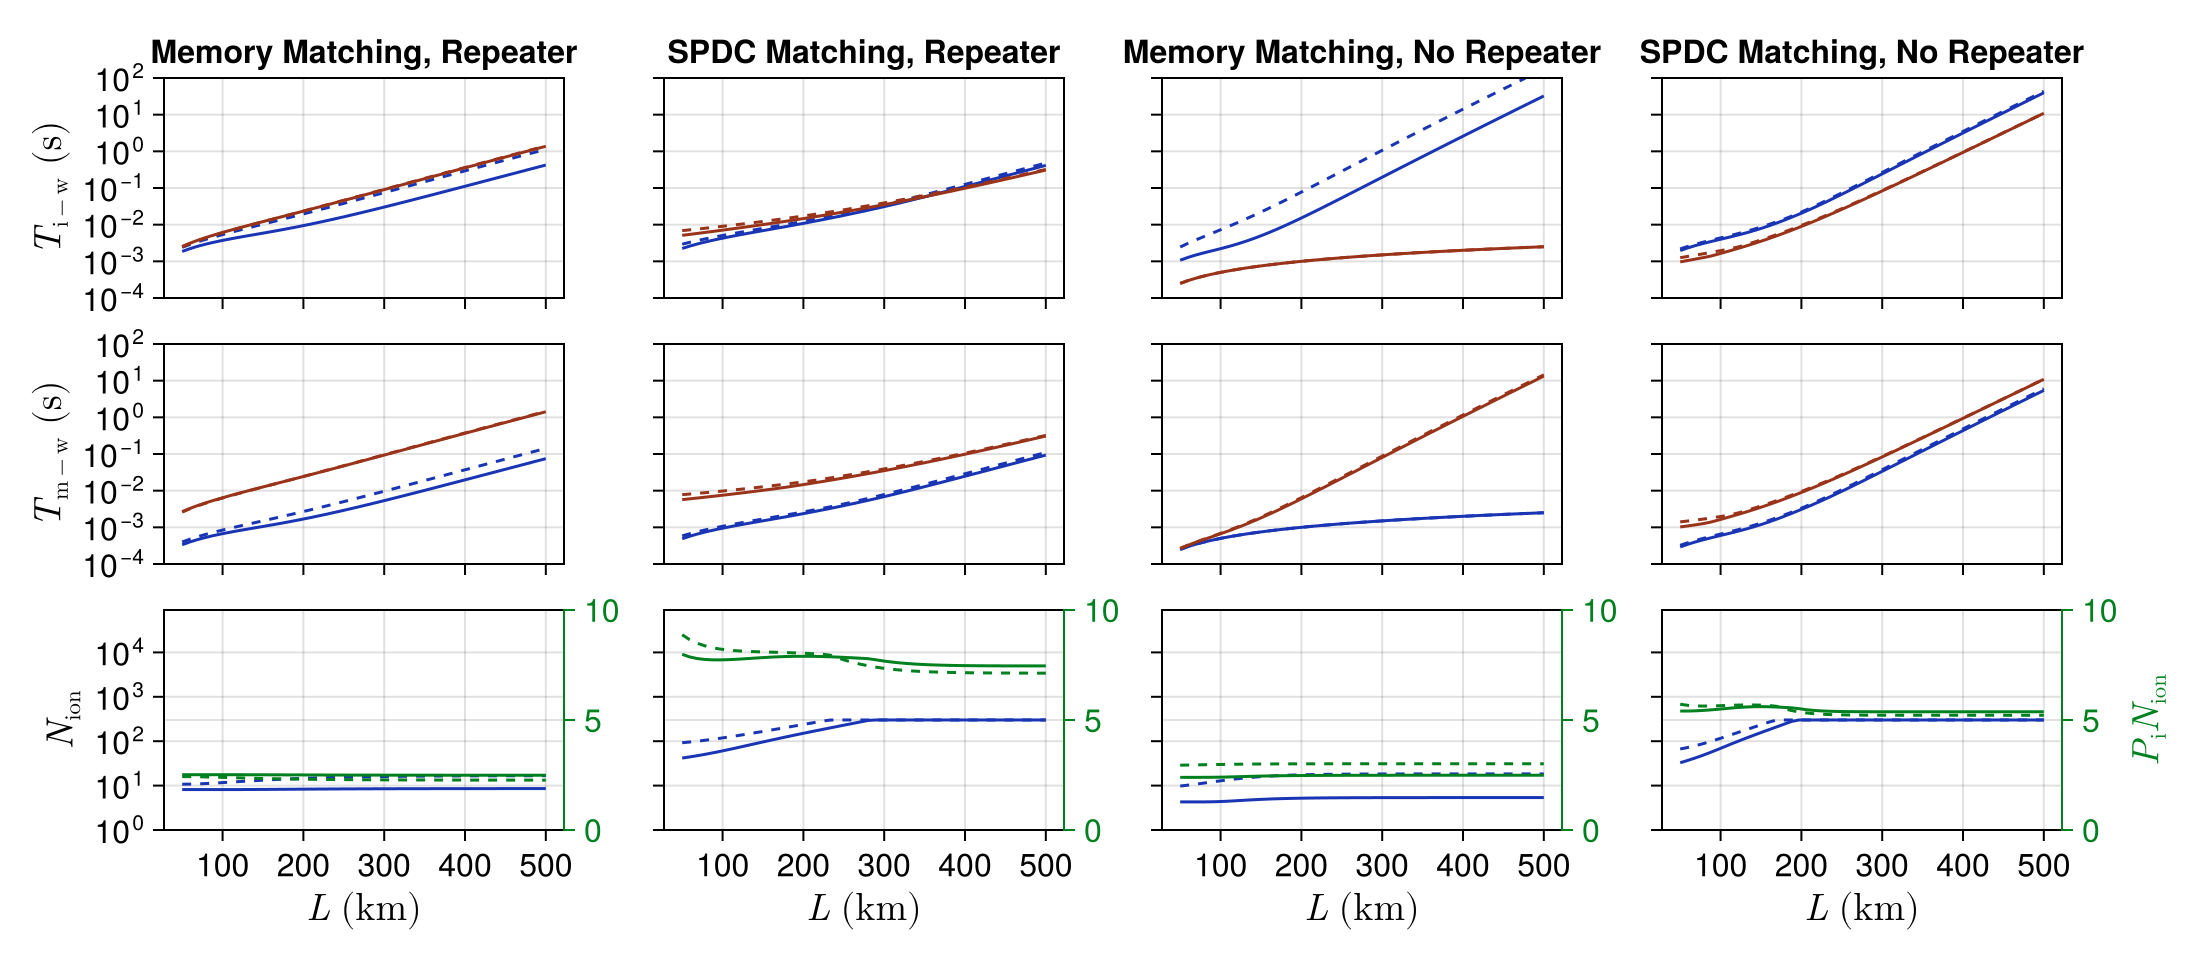

In [6]:
fig3 = Figure(size = (1100, 480))

C_red  = RGBf(0.6,0.2,0.1)
C_blue = RGBf(0.1,0.21,0.7)
C_right = RGBf(0.0,0.5,.12)
f_size, t_size, y_size, leg_size = 16, 16, 19, 14
ylm   = (1e-4, 1e2)
ylm_n = (1, 9e4)
ylm_nr = (0,10)

colors = Dict(:SC => C_blue, :DC => C_red)
linestyles = Dict(:on => :dash, :off => :solid)

columns = [
    (M_M_results,    :repeater,    "Memory Matching, Repeater"),
    (SPDC_M_results, :repeater,    "SPDC Matching, Repeater"),
    (M_M_results,    :no_repeater, "Memory Matching, No Repeater"),
    (SPDC_M_results, :no_repeater, "SPDC Matching, No Repeater")
]

# Row 1: T_i-w
for (j, (dataset, repeater_label, title)) in enumerate(columns)
    ax = Axis(fig3[1, j], xlabel = "", ylabel = j == 1 ? L"T_{\mathrm{i-w}}\ \mathrm{(s)}" : "", yscale = log10,
        yticklabelsvisible = j == 1, xticklabelsvisible = false, title = title, xlabelsize = y_size, ylabelsize = y_size,
        titlesize = t_size, xticklabelsize = f_size, yticklabelsize = f_size)
    ylims!(ax, ylm)
    for sc_label in (:SC, :DC)
        for turn_label in (:on, :off)
            suffix = turn_label == :off ? ", turn-off" : ""
            T_i_w = getindex.(dataset[(sc_label, turn_label, repeater_label)], 3)
            lines!(ax, L_array ./ 1e3, T_i_w; color = colors[sc_label], linestyle = linestyles[turn_label], label = "$(sc_label)$suffix")
        end
    end
end

# Row 2: T_m-w
for (j, (dataset, repeater_label, _)) in enumerate(columns)
    ax = Axis(fig3[2, j], xlabel = "", ylabel = j == 1 ? L"T_{\mathrm{m-w}}\ \mathrm{(s)}" : "", yscale = log10,
        yticklabelsvisible = j == 1, xticklabelsvisible = false, xlabelsize = y_size, ylabelsize = y_size, titlesize = t_size,
        xticklabelsize = f_size, yticklabelsize = f_size)
    ylims!(ax, ylm)
    for sc_label in (:SC, :DC)
        for turn_label in (:on, :off)
            suffix = turn_label == :off ? ", turn-off" : ""
            T_m_w = getindex.(dataset[(sc_label, turn_label, repeater_label)], 2)
            lines!(ax, L_array ./ 1e3, T_m_w; color = colors[sc_label], linestyle = linestyles[turn_label], label = "$(sc_label)$suffix")
        end
    end
end
# Row 3: N_ion
for (j, (dataset, repeater_label, _)) in enumerate(columns)
    # Left axis
    ax = Axis(fig3[3, j], xlabel = L"L\;(\mathrm{km})", ylabel = j == 1 ? L"N_{\mathrm{ion}}" : "",
        yscale = log10, yticklabelsvisible = j == 1, xlabelsize = y_size, ylabelsize = y_size, titlesize = t_size,
        xticklabelsize = f_size ,yticklabelsize = f_size)
    ylims!(ax, ylm_n)

    # Right axis
    axr = Axis(fig3[3, j], yaxisposition = :right, ylabel = j == 4 ?  L"P_{\mathrm{i}} N_{\mathrm{ion}}" : "",
        xticksvisible = false, xticklabelsvisible = false, xgridvisible = false,
        yticklabelcolor = C_right, ytickcolor = C_right, rightspinecolor = C_right, ylabelcolor = C_right,
        ylabelsize = y_size, yticklabelsize = f_size)
    ylims!(axr, ylm_nr)
    # Hide the duplicate background
    hidespines!(axr, :l, :b, :t)
    hidexdecorations!(axr)
    for sc_label in (:SC, :DC), turn_label in (:on, :off)
        suffix = turn_label == :off ? ", turn-off" : ""
        N_ion = getindex.(dataset[(sc_label, turn_label, repeater_label)], 4)
        P_ion = getindex.(dataset[(sc_label, turn_label, repeater_label)], 5)
        if sc_label == :SC
            lines!(ax, L_array ./ 1e3, N_ion; color = C_blue, linestyle = linestyles[turn_label]) 
            lines!(axr, L_array ./ 1e3, N_ion.*P_ion; color = C_right, linestyle = linestyles[turn_label])
        end
    end
end
fig3

In [7]:
##We now do the same for Parameter Set II

#NOTE: we reuse the same data names for simplicity, so the following cells will overwrite the data in the ones above for PSet I

In [8]:
global_logger(ConsoleLogger())   # new logger for error message (since it only outputs once per kernel if you don't do this), maxlog counts start from zero
##### parameters set II - more realistic values
N_cap = 6000
F_targ= 0.9 #target fidelity
η_m, η_FC, η_i_io,  η_AFC0 = fill(0.4,4)
η_d = 0.75
η_herald = 0.92
effs = (η_m, η_d, η_i_io, η_FC, η_AFC0, η_herald);
effs_SPDC = (η_m, η_d, η_i_io, η_FC, η_herald);
N_bin=10 
M=500 #multiplexing modes
r=0.4 #dephasing parameter
epsilon_m=0.5; nu = 1; Lambda_0= nu/2; filt_params = (Lambda_0, nu, epsilon_m); #low pass filter parameters
T_EN = 50*1e-6; #effective time between ion pulse attempts

In [9]:
###Generate data

L_array = range(50,500,length=50)*1e3 #range of total distances, in meters
M_M_results = Dict(); #initialize memory matching results

for (sc_label, sc_key) in [(:SC, true), (:DC, false)]
    for (repeater_label, repeater_key) in [(:repeater, 1), (:no_repeater, 0)]
        for (turn_label, turn_key) in [(:on, false), (:off, true)]
            M_M_results[(sc_label, turn_label, repeater_label)] = map(L -> Memory_Match(
                repeater_key, L, effs, F_targ, M, filt_params;
                single_click = sc_key,
                r = r,
                turn_off = turn_key
            ), L_array)
        end
    end
end
#We can access the parameters,
#T_ent, T_m_w, T_i_w, N_ion, P_i, P_SPDC, F_0 = M_M_results[(:SC/:DC, :on/:off, :repeater/:no_repeater)],
#Where each of the output is a vector as a function of distance

SPDC_M_results = Dict();
# We tie the SPDC (memory) turn-off to the ion turn-off. For SC it has no effect at the order considered; for DC it enters only through I_0 and κ_0 (a small effect).
for (sc_label, sc_key) in [(:SC, true), (:DC, false)]
    for (repeater_label, repeater_key) in [(:repeater, 1), (:no_repeater, 0)]
        for (turn_label, turn_key) in [(:on, false), (:off, true)]
            SPDC_M_results[(sc_label, turn_label, repeater_label)] = map(L -> SPDC_Match(
                repeater_key, L, effs_SPDC, F_targ, M, N_bin, T_EN;
                single_click = sc_key,
                r = r,
                N_cap = N_cap,
                turn_off = turn_key,
                turn_off_mem = turn_key
            ), L_array)
        end
    end
end
#We can access the parameters,
#T_ent, T_m_w, T_i_w, N_ion, P_i, P_SPDC, P_b = SPDC_M_results[(:SC/:DC, :on/:off, :repeater/:no_repeater)],
#Where each of the output is a vector as a function of distance

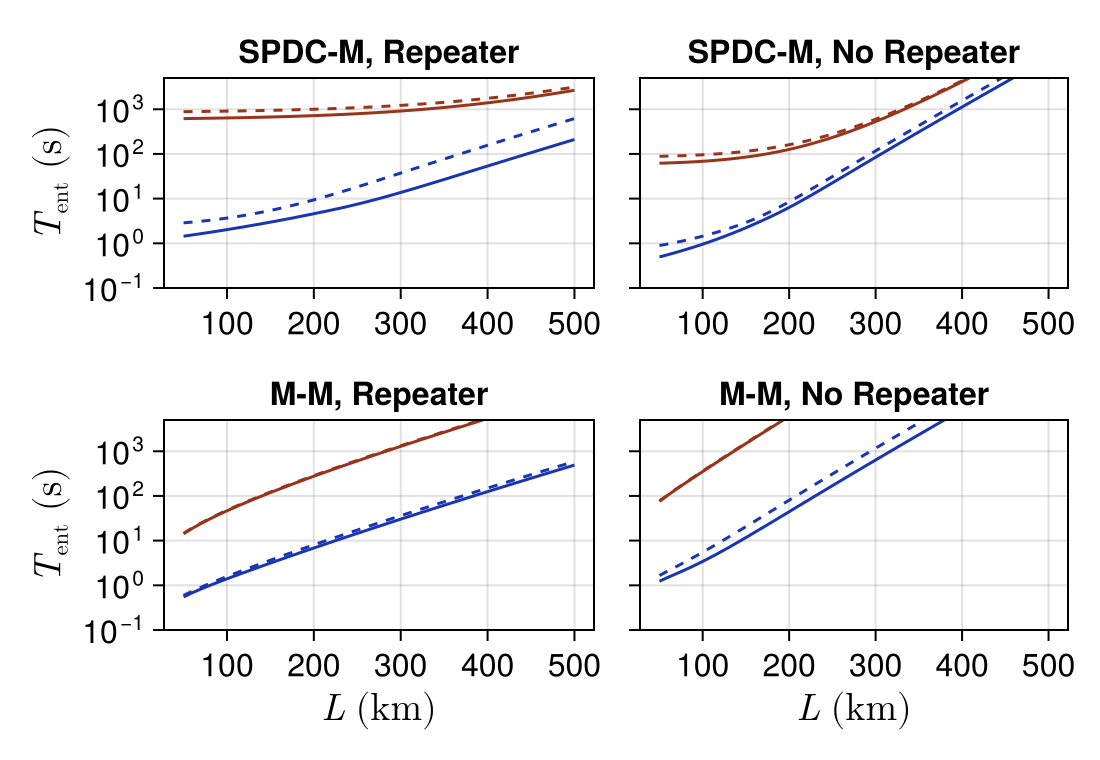

In [10]:
fig4 = Figure(size = (550, 380))
C_red  = RGBf(0.6,0.2,0.1); C_blue = RGBf(0.1,0.21,0.7)
f_size, t_size, y_size, leg_size = 16, 16, 19, 14
ylm = (1e-1, 5e3);
colors = Dict(:SC => C_blue, :DC => C_red)
linestyles = Dict(:on => :dash, :off => :solid)
linestyle_labels = Dict(:on => "", :off  => "turn-off")
titles = [    "SPDC-M, Repeater"        "SPDC-M, No Repeater"; "M-M, Repeater"      "M-M, No Repeater"]
for (i, dataset) in enumerate((SPDC_M_results, M_M_results))
    for (j, repeater_label) in enumerate((:repeater, :no_repeater))
        ax = Axis(fig4[i, j],ylabel = j ==  1 ?  L"T_{\mathrm{ent}} \  \mathrm{(s)}" : "", yticklabelsvisible = (j == 1),xlabel = i == 2 ?  L"L\;(\mathrm{km})" : "", yscale = log10, title = titles[i,j], xlabelsize = y_size, ylabelsize = y_size, titlesize = t_size, xticklabelsize = f_size, yticklabelsize = f_size)
        ylims!(ax, ylm)
        for sc_label in (:SC, :DC)
            for turn_label in (:on, :off)
                T_ent = first.(dataset[(sc_label, turn_label, repeater_label)])
                lines!(ax, L_array ./ 1e3, T_ent; color = colors[sc_label], linestyle = linestyles[turn_label], label = "$(sc_label), $(linestyle_labels[turn_label])")
            end
        end
    end
end

fig4

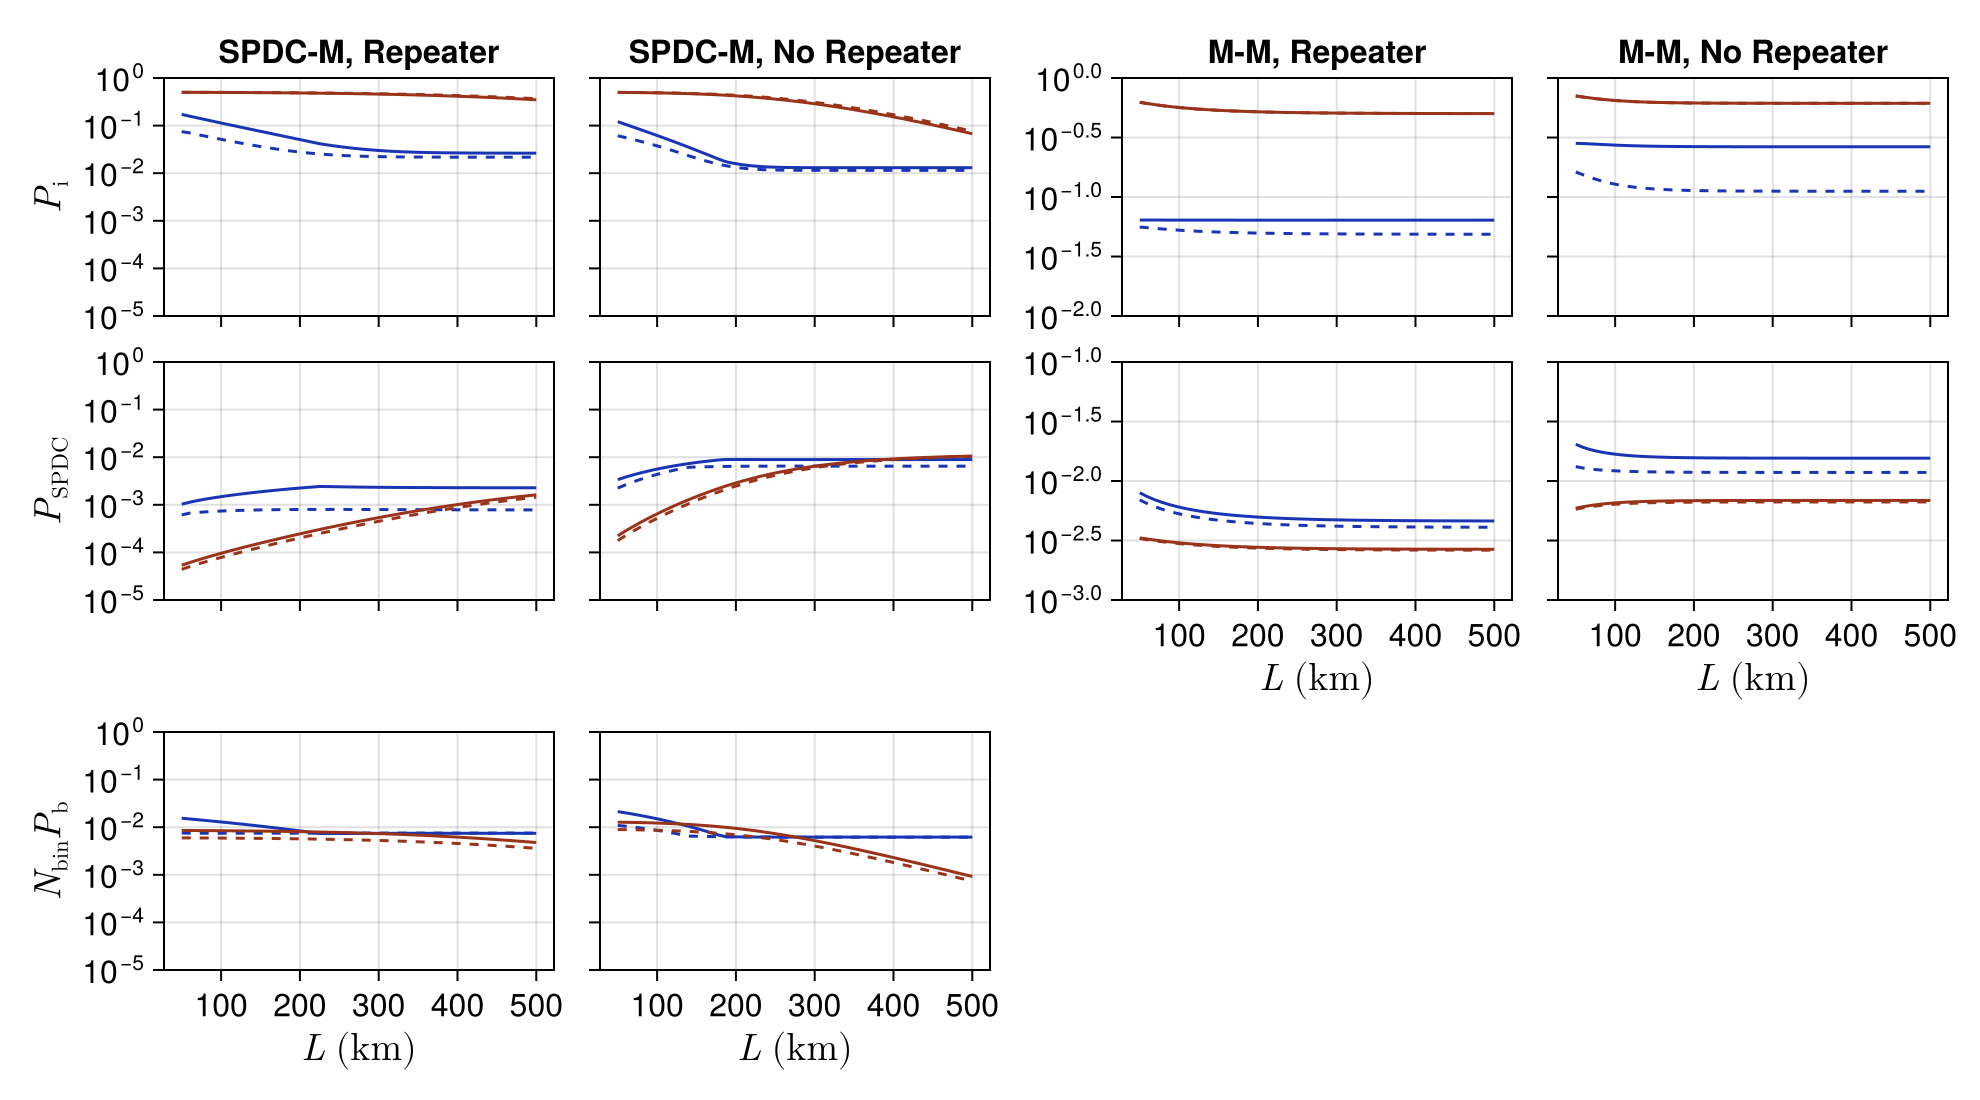

In [11]:
fig5 = Figure(size = (990, 550))

ylm = (1e-5, 1)
titles = ["SPDC-M, Repeater"  "SPDC-M, No Repeater"]
rows = [(5, L"P_{\mathrm{i}}"), (6, L"P_{\mathrm{SPDC}}"), (7, L"N_{\mathrm{bin}}P_{\mathrm{b}}")]

for (j, repeater_label) in enumerate((:repeater, :no_repeater))
    for (row, (idx, ylab)) in enumerate(rows)
        ax = Axis(fig5[row, j], ylabel = j == 1 ? ylab : "", xlabel = row == 3 ? L"L\;(\mathrm{km})" : "", yscale = log10, yticklabelsvisible = (j == 1), xticklabelsvisible = (row == 3),
            title = row == 1 ? titles[j] : "", xlabelsize = y_size, ylabelsize = y_size, titlesize = t_size, xticklabelsize = f_size, yticklabelsize = f_size)
        ylims!(ax, ylm)
        for sc_label in (:SC, :DC), turn_label in (:on, :off)
            vals = getindex.(SPDC_M_results[(sc_label, turn_label, repeater_label)], idx)
            fac = row == 3 ? N_bin : 1
            lines!(ax, L_array ./ 1e3, vals*fac; color = colors[sc_label], linestyle = linestyles[turn_label], label = "$(sc_label), $(linestyle_labels[turn_label])")
        end
    end
end

titles2 = ["M-M, Repeater"  "M-M, No Repeater"]
rows2 = [(5, L"P_{\mathrm{i}}"), (6, L"P_{\mathrm{SPDC}}")]
ylm2 = (1e-2, 1); ylm3 = (1e-3,1e-1);
for (j, repeater_label) in enumerate((:repeater, :no_repeater))
    for (row, (idx, ylab)) in enumerate(rows2)
        ax = Axis(fig5[row, j + 2], ylabel = "", xlabel = row == 2 ? L"L\;(\mathrm{km})" : "", yscale = log10, yticklabelsvisible = (j==1), xticklabelsvisible = (row == 2),
            title = row == 1 ? titles2[j] : "", xlabelsize = y_size, ylabelsize = y_size, titlesize = t_size, xticklabelsize = f_size, yticklabelsize = f_size)
        if row == 1 ylims!(ax, ylm2) else ylims!(ax, ylm3) end
        for sc_label in (:SC, :DC), turn_label in (:on, :off)
            vals = getindex.(M_M_results[(sc_label, turn_label, repeater_label)], idx)
            lines!(ax, L_array ./ 1e3, vals; color = colors[sc_label], linestyle = linestyles[turn_label], label = "$(sc_label), $(linestyle_labels[turn_label])")
        end
    end
end

fig5

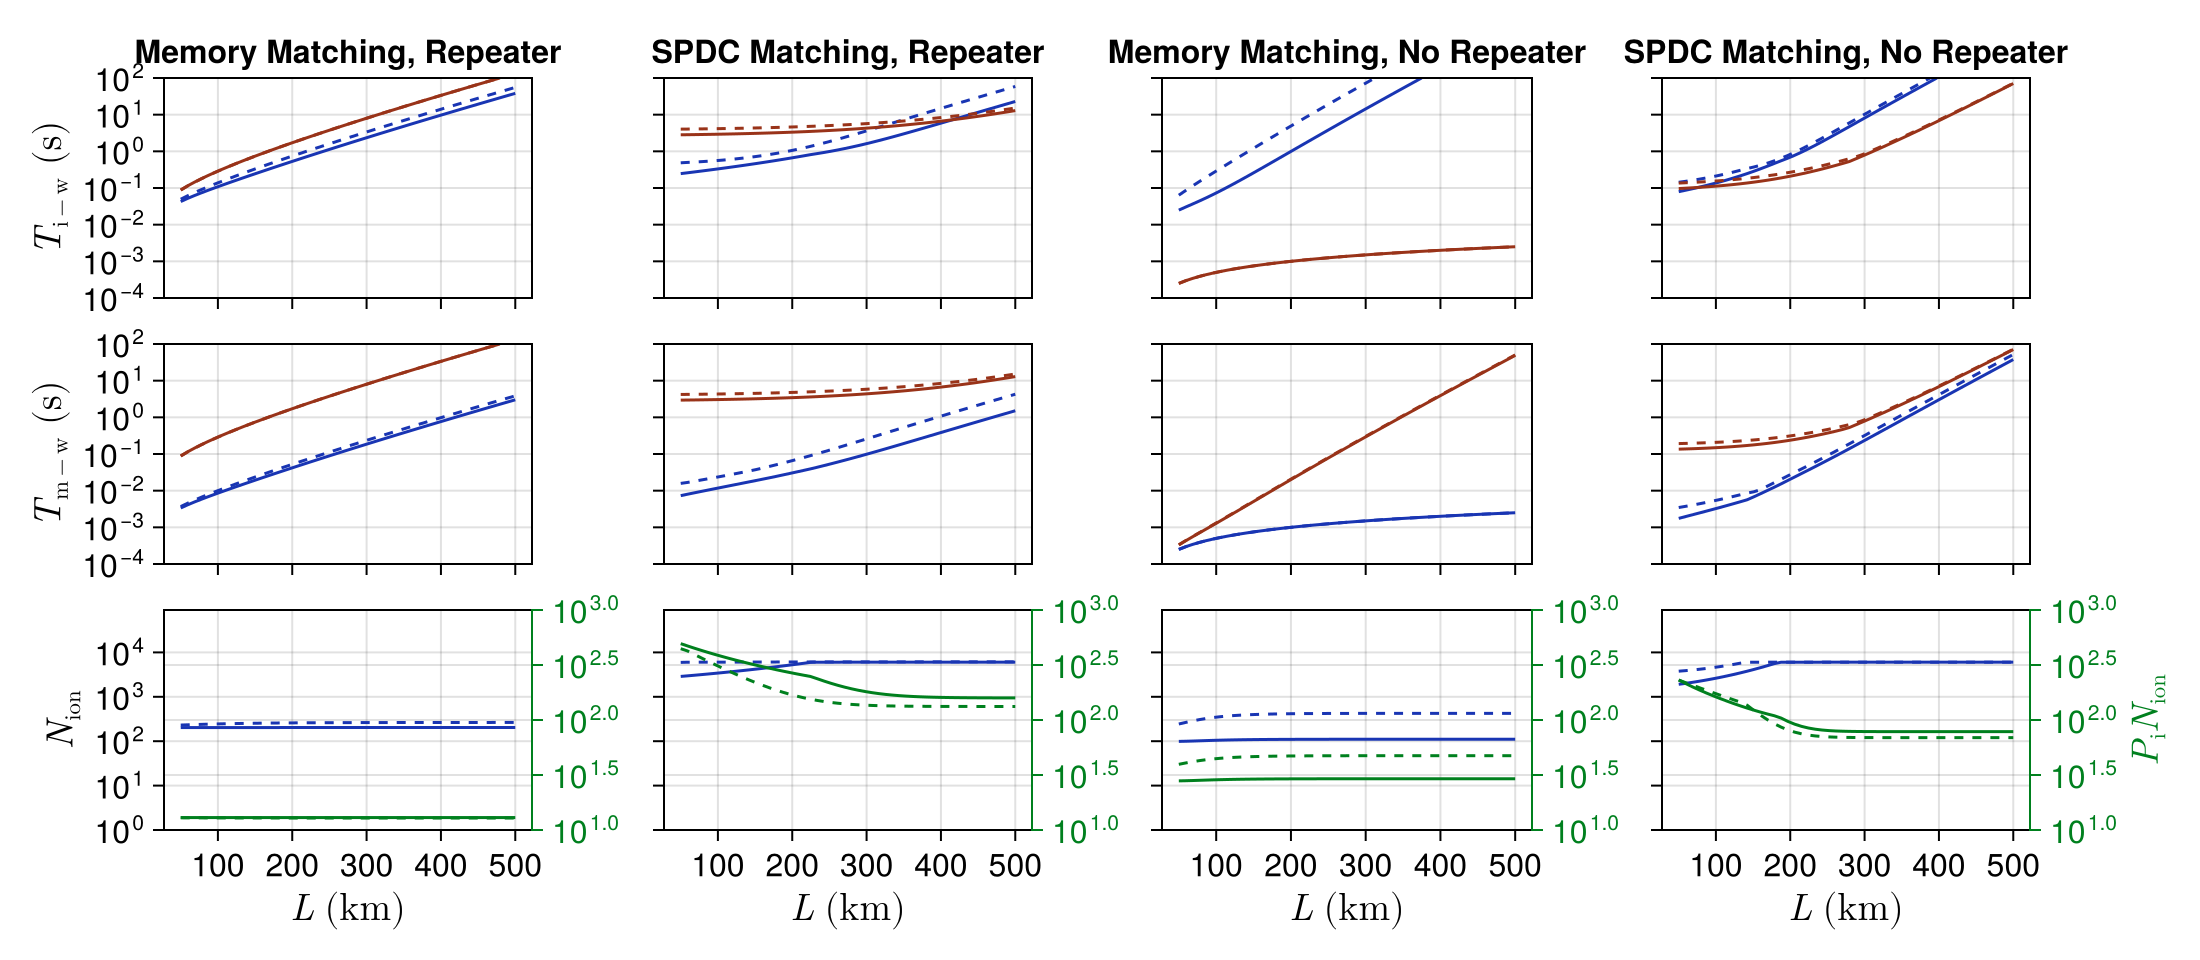

In [12]:
fig6 = Figure(size = (1100, 480))

C_red  = RGBf(0.6,0.2,0.1)
C_blue = RGBf(0.1,0.21,0.7)
C_right = RGBf(0.0,0.5,.12)
f_size, t_size, y_size, leg_size = 16, 16, 19, 14
ylm   = (1e-4, 1e2)
ylm_n = (1, 9e4)
ylm_nr = (10,1000)

colors = Dict(:SC => C_blue, :DC => C_red)
linestyles = Dict(:on => :dash, :off => :solid)

columns = [
    (M_M_results,    :repeater,    "Memory Matching, Repeater"),
    (SPDC_M_results, :repeater,    "SPDC Matching, Repeater"),
    (M_M_results,    :no_repeater, "Memory Matching, No Repeater"),
    (SPDC_M_results, :no_repeater, "SPDC Matching, No Repeater")
]

# Row 1: T_i-w
for (j, (dataset, repeater_label, title)) in enumerate(columns)
    ax = Axis(fig6[1, j], xlabel = "", ylabel = j == 1 ? L"T_{\mathrm{i-w}}\ \mathrm{(s)}" : "", yscale = log10,
        yticklabelsvisible = j == 1, xticklabelsvisible = false, title = title, xlabelsize = y_size, ylabelsize = y_size,
        titlesize = t_size, xticklabelsize = f_size, yticklabelsize = f_size)
    ylims!(ax, ylm)
    for sc_label in (:SC, :DC)
        for turn_label in (:on, :off)
            suffix = turn_label == :off ? ", turn-off" : ""
            T_i_w = getindex.(dataset[(sc_label, turn_label, repeater_label)], 3)
            lines!(ax, L_array ./ 1e3, T_i_w; color = colors[sc_label], linestyle = linestyles[turn_label], label = "$(sc_label)$suffix")
        end
    end
end

# Row 2: T_m-w
for (j, (dataset, repeater_label, _)) in enumerate(columns)
    ax = Axis(fig6[2, j], xlabel = "", ylabel = j == 1 ? L"T_{\mathrm{m-w}}\ \mathrm{(s)}" : "", yscale = log10,
        yticklabelsvisible = j == 1, xticklabelsvisible = false, xlabelsize = y_size, ylabelsize = y_size, titlesize = t_size,
        xticklabelsize = f_size, yticklabelsize = f_size)
    ylims!(ax, ylm)
    for sc_label in (:SC, :DC)
        for turn_label in (:on, :off)
            suffix = turn_label == :off ? ", turn-off" : ""
            T_m_w = getindex.(dataset[(sc_label, turn_label, repeater_label)], 2)
            lines!(ax, L_array ./ 1e3, T_m_w; color = colors[sc_label], linestyle = linestyles[turn_label], label = "$(sc_label)$suffix")
        end
    end
end
# Row 3: N_ion
for (j, (dataset, repeater_label, _)) in enumerate(columns)
    # Left axis
    ax = Axis(fig6[3, j], xlabel = L"L\;(\mathrm{km})", ylabel = j == 1 ? L"N_{\mathrm{ion}}" : "",
        yscale = log10, yticklabelsvisible = j == 1, xlabelsize = y_size, ylabelsize = y_size, titlesize = t_size,
        xticklabelsize = f_size ,yticklabelsize = f_size)
    ylims!(ax, ylm_n)

    # Right axis
    axr = Axis(fig6[3, j], yaxisposition = :right, ylabel = j == 4 ?  L"P_{\mathrm{i}} N_{\mathrm{ion}}" : "",
        xticksvisible = false, xticklabelsvisible = false, xgridvisible = false, yscale=log10,
        yticklabelcolor = C_right, ytickcolor = C_right, rightspinecolor = C_right, ylabelcolor = C_right,
        ylabelsize = y_size, yticklabelsize = f_size)
    ylims!(axr, ylm_nr)
    # Hide the duplicate background
    hidespines!(axr, :l, :b, :t)
    hidexdecorations!(axr)
    for sc_label in (:SC, :DC), turn_label in (:on, :off)
        suffix = turn_label == :off ? ", turn-off" : ""
        N_ion = getindex.(dataset[(sc_label, turn_label, repeater_label)], 4)
        P_ion = getindex.(dataset[(sc_label, turn_label, repeater_label)], 5)
        if sc_label == :SC
            lines!(ax, L_array ./ 1e3, N_ion; color = colors[sc_label], linestyle = linestyles[turn_label]) 
            lines!(axr, L_array ./ 1e3, N_ion.*P_ion; color = C_right, linestyle = linestyles[turn_label])
        end
    end
end

fig6